In [1]:
!pip install -q koreanize-matplotlib openpyxl
import pandas as pd, numpy as np, re, glob
import matplotlib.pyplot as plt
import koreanize_matplotlib
from google.colab import files
pd.set_option('display.max_columns', None)

In [2]:
uploaded = files.upload()
fac_files = list(uploaded.keys())
print(fac_files)

Saving facilities.csv to facilities.csv
['facilities.csv']


In [8]:
df = raw['facilities.csv']
print(df.shape)
print(df.columns.tolist())
df.head(3)

(60, 34)
['id', 'name', 'type', 'gu', 'dong', 'address', 'phone', 'lat', 'lng', 'age_min', 'age_max', 'all_ages', 'semester_open', 'semester_close', 'vacation_open', 'vacation_close', 'saturday_open', 'saturday_close', 'temp_semester_open', 'temp_semester_close', 'temp_vacation_open', 'temp_vacation_close', 'fee_type', 'fee_unit', 'fee_amount', 'meal', 'snack', 'pickup', 'capacity', 'temp_capacity', 'programs', 'application_info', 'source', 'verified_at']


,id,name,type,gu,dong,address,phone,lat,lng,age_min,age_max,all_ages,semester_open,semester_close,vacation_open,vacation_close,saturday_open,saturday_close,temp_semester_open,temp_semester_close,temp_vacation_open,temp_vacation_close,fee_type,fee_unit,fee_amount,meal,snack,pickup,capacity,temp_capacity,programs,application_info,source,verified_at
0,YI00250031,용인시 다함께돌봄센터 1호점,다함께돌봄센터,처인구,고림동,"경기 용인시 처인구 경안천로 112 고림동, 양우내안애에듀파크",031-321-2511,NaN,NaN,6.0,12.0,False,13:00,19:00,09:00,19:00,NaN,NaN,09:00,19:00,09:00,19:00,paid,day,2200.0,True,True,NaN,23.0,3.0,"보호 프로그램: 일상생활, 위생건강 관리, 급식지도, 안전귀가지도, 5대안전의무교육...",용인시 다함께돌봄센터 1호점에서는 초등돌봄반 정기돌봄 인원 23명과 일시돌봄 인원 ...,경기도 아동언제나돌봄 우리동네 돌봄자원 찾기,2026-10-29
1,YI00250032,용인시 다함께돌봄센터 2호점,다함께돌봄센터,기흥구,구갈동,"경기 용인시 기흥구 기흥역로 63 구갈동, 힐스테이트기흥, 관리동 5층 유컬트허브 내",031-281-2513,NaN,NaN,6.0,12.0,False,10:00,19:00,09:00,19:00,NaN,NaN,10:00,19:00,09:00,19:00,free,NaN,0.0,True,True,NaN,NaN,NaN,"보호 프로그램: 출결확인, 위생.청결지도, 일상생활지도 / 교육 프로그램: 만들기활...",NaN,경기도 아동언제나돌봄 우리동네 돌봄자원 찾기,2026-10-29
2,YI00250033,용인시다함께돌봄센터 3호점,다함께돌봄센터,처인구,역북동,"경기 용인시 처인구 명지로16번길 26 역북동, 동원로얄듀크, 공동시설동 지하1층",031-335-3294,NaN,NaN,6.0,12.0,False,09:00,19:00,09:00,19:00,NaN,NaN,09:00,19:00,09:00,19:00,free,NaN,0.0,NaN,True,NaN,44.0,2.0,"보호 프로그램: 일상생활, 위생건강 관리, 방학중급식지도, 안전귀가지도, 5대안전의...",용인시 다함께돌봄센터 3호점은 초등 정기돌봄 인원 44명과 일시돌봄 인원 2명 기준...,경기도 아동언제나돌봄 우리동네 돌봄자원 찾기,2026-10-29


In [3]:
def read_any(path):
    if path.endswith('.csv'):
        for enc in ['utf-8-sig', 'cp949', 'euc-kr']:
            try: return pd.read_csv(path, encoding=enc)
            except UnicodeDecodeError: continue
    return pd.read_excel(path)

raw = {f: read_any(f) for f in fac_files}
for f, df in raw.items():
    print(f'=== {f} ({len(df)}행) ===')
    print(list(df.columns), '\n')

=== facilities.csv (60행) ===
['id', 'name', 'type', 'gu', 'dong', 'address', 'phone', 'lat', 'lng', 'age_min', 'age_max', 'all_ages', 'semester_open', 'semester_close', 'vacation_open', 'vacation_close', 'saturday_open', 'saturday_close', 'temp_semester_open', 'temp_semester_close', 'temp_vacation_open', 'temp_vacation_close', 'fee_type', 'fee_unit', 'fee_amount', 'meal', 'snack', 'pickup', 'capacity', 'temp_capacity', 'programs', 'application_info', 'source', 'verified_at'] 



In [9]:
fac = raw['facilities.csv'].copy()
N = len(fac)

# ① 정보가 어디 있는지: 유형별 출처
tA = (fac.groupby('type')
        .agg(시설수=('id', 'count'),
             출처수=('source', 'nunique'),
             출처=('source', lambda x: ' / '.join(x.dropna().unique())))
        .reset_index().rename(columns={'type': '시설유형'}))

# ①④ 항목별 정보 제공률: 부모가 알고 싶은 정보가 얼마나 공개돼 있나
FIELDS = {'전화번호': 'phone', '정원': 'capacity', '이용료': 'fee_type',
          '학기중 운영시간': 'semester_open', '방학 운영시간': 'vacation_open',
          '토요일 운영': 'saturday_open', '급식': 'meal', '간식': 'snack',
          '귀가 지원': 'pickup', '프로그램': 'programs', '신청 방법 안내': 'application_info'}
tB = (pd.DataFrame([(k, fac[v].notna().mean() * 100) for k, v in FIELDS.items()],
                   columns=['정보 항목', '제공률(%)'])
        .round(0).sort_values('제공률(%)').reset_index(drop=True))

# ③ 유형마다 이용 조건이 다름
tC = (fac.groupby('type')
        .agg(시설수=('id', 'count'),
             이용연령=('age_min', lambda x: f"{x.min():.0f}~{fac.loc[x.index, 'age_max'].max():.0f}세"),
             연령기준_종류=('age_min', lambda x: fac.loc[x.index, ['age_min', 'age_max']].drop_duplicates().shape[0]),
             유료비율=('fee_type', lambda x: f"{(x == 'paid').mean() * 100:.0f}%"),
             요금단위=('fee_unit', lambda x: ', '.join(x.dropna().astype(str).unique()) or '-'),
             운영시간_패턴수=('semester_open', lambda x: fac.loc[x.index, ['semester_open', 'semester_close']].drop_duplicates().shape[0]))
        .reset_index().rename(columns={'type': '시설유형'}))

# 구별 분포 (참고)
tD = pd.crosstab(fac['gu'], fac['type'], margins=True, margins_name='합계')

print(f"분석 대상: 용인시 아동 돌봄·배움 시설 {N}곳 (수집일 {fac['verified_at'].max()})")
for t in [tA, tB, tC, tD]: display(t)

분석 대상: 용인시 아동 돌봄·배움 시설 60곳 (수집일 2026-10-29)


,시설유형,시설수,출처수,출처
0,다함께돌봄센터,26,1,경기도 아동언제나돌봄 우리동네 돌봄자원 찾기
1,지역아동센터,34,1,경기도 아동언제나돌봄 우리동네 돌봄자원 찾기


,정보 항목,제공률(%)
0,토요일 운영,13.0
1,귀가 지원,27.0
2,정원,38.0
3,신청 방법 안내,47.0
4,급식,87.0
5,간식,98.0
6,방학 운영시간,98.0
7,학기중 운영시간,98.0
8,프로그램,98.0
9,이용료,100.0


,시설유형,시설수,이용연령,연령기준_종류,유료비율,요금단위,운영시간_패턴수
0,다함께돌봄센터,26,6~13세,3,8%,"day, month",6
1,지역아동센터,34,5~19세,15,0%,-,10


type,다함께돌봄센터,지역아동센터,합계
gu,,,
기흥구,8,14,22
수지구,5,4,9
처인구,13,16,29
합계,26,34,60


In [10]:
age_combo = fac[['age_min', 'age_max']].drop_duplicates().shape[0]
fee_combo = fac[['fee_type', 'fee_unit']].drop_duplicates().shape[0]
hour_combo = fac[['semester_open', 'semester_close']].drop_duplicates().shape[0]
info_rate = tB['제공률(%)'].mean()

rows = [
    ['① 시설·프로그램 정보 찾기 어렵다', '정보를 모으기 위해 확인한 출처 수', f"{fac['source'].nunique()}곳"],
    ['', '시설 유형 수 (유형마다 안내 채널이 다름)', f"{fac['type'].nunique()}개"],
    ['', '부모가 궁금한 정보 11개 항목 평균 공개율', f"{info_rate:.0f}%"],
    ['③ 지원 대상인지 판단 어렵다', '서로 다른 이용 연령 기준', f"{age_combo}가지"],
    ['', '서로 다른 요금 체계', f"{fee_combo}가지"],
    ['', '서로 다른 학기중 운영시간', f"{hour_combo}가지"],
    ['④ 신청 방법 일일이 확인해야 한다', '신청 방법 안내가 없는 시설 비율', f"{fac['application_info'].isna().mean() * 100:.0f}%"],
    ['', '정원 정보가 없는 시설 비율', f"{fac['capacity'].isna().mean() * 100:.0f}%"],
]

# ② 정책 데이터를 셀 11~13으로 불러왔으면 자동 추가
if 'pol' in globals():
    rows[3:3] = [
        ['② 지원 정책이 흩어져 있다', '아동 정책 소관기관 수', f"{pol['소관기관'].nunique()}곳"],
        ['', '서로 다른 신청 채널 종류', f"{pol['신청채널'].explode().nunique()}가지"],
    ]

evidence = pd.DataFrame(rows, columns=['페르소나 문제점', '근거 지표', '수치'])
display(evidence.style.hide(axis='index'))

페르소나 문제점,근거 지표,수치
① 시설·프로그램 정보 찾기 어렵다,정보를 모으기 위해 확인한 출처 수,1곳
,시설 유형 수 (유형마다 안내 채널이 다름),2개
,부모가 궁금한 정보 11개 항목 평균 공개율,73%
③ 지원 대상인지 판단 어렵다,서로 다른 이용 연령 기준,15가지
,서로 다른 요금 체계,4가지
,서로 다른 학기중 운영시간,13가지
④ 신청 방법 일일이 확인해야 한다,신청 방법 안내가 없는 시설 비율,53%
,정원 정보가 없는 시설 비율,62%


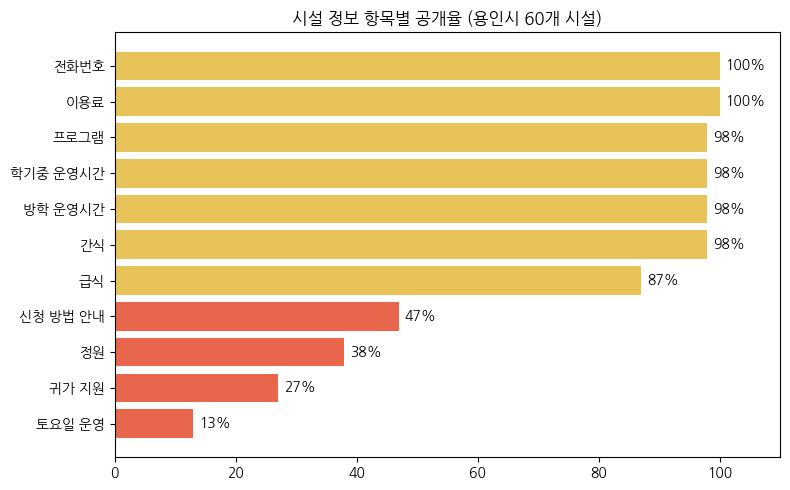

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
plt.figure(figsize=(8, 5))
colors = ['#E8664B' if v < 50 else '#E8C35A' for v in tB['제공률(%)']]
plt.barh(tB['정보 항목'], tB['제공률(%)'], color=colors)
for i, v in enumerate(tB['제공률(%)']):
    plt.text(v + 1, i, f'{v:.0f}%', va='center')
plt.xlim(0, 110); plt.title(f'시설 정보 항목별 공개율 (용인시 {N}개 시설)')
plt.tight_layout(); plt.savefig('정보공개율.png', dpi=200); plt.show()

with pd.ExcelWriter('페르소나_근거표.xlsx') as w:
    evidence.to_excel(w, sheet_name='근거표_요약', index=False)
    tA.to_excel(w, sheet_name='유형별_출처', index=False)
    tB.to_excel(w, sheet_name='항목별_공개율', index=False)
    tC.to_excel(w, sheet_name='유형별_이용조건', index=False)
    tD.to_excel(w, sheet_name='구별_분포')
for f in ['페르소나_근거표.xlsx', '정보공개율.png']:
    files.download(f)